In [2]:
import pandas as pd
from sklearn.model_selection import train_test_split
import re
from collections import Counter
import numpy as np
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt
from math import nan

SEED=2
np.random.seed(SEED)

In [3]:
class DataPreProcessor:
    farsi_pattern = re.compile(r"[^\u0621-\u064A\u067E\u0686\u0698\u06AF\u06CC\u06A9\s]+")
    space_pattern = re.compile(r'\s+')

    def __init__(self):
        self.df = None
        self.X_train = None
        self.X_test = None
        self.y_train = None
        self.y_test = None

    def read_data(self, df_path):
       self.df = pd.read_csv(df_path)
       return self.df

    def split_data(self, test_size):
        if self.df is None:
            print("DataFrame is null.")
            return None, None, None, None

        X = self.df['Text']
        y = self.df['Topic']

        self.X_train, self.X_test, self.y_train, self.y_test = train_test_split(X, y, test_size=test_size, random_state=2)
        return self.X_train, self.X_test, self.y_train, self.y_test

    def clean_to_farsi_only(self, text):
        if not isinstance(text, str):
          return ""
        cleaned_text_local = self.farsi_pattern.sub(' ', text)
        cleaned_text_local = self.space_pattern.sub(' ', cleaned_text_local).strip().lower()
        return cleaned_text_local

    def clean_text(self):
        if self.X_train is not None and self.X_test is not None:
            self.X_train = self.X_train.apply(self.clean_to_farsi_only)
            self.X_test = self.X_test.apply(self.clean_to_farsi_only)


            return self.X_train, self.X_test
        else:
            print("X_train or X_test are null")
            return None, None

In [4]:
from math import nan
class NaiveBayesClassifier:

    def __init__(self, X_train_clean,X_test_clean, y_train, y_test):

      self.X_train_clean = X_train_clean
      self.X_test_clean = X_test_clean
      self.y_train = y_train
      self.y_test = y_test

      self.smoothing_param = 1
      self.word_counts_per_class = None
      self.unique_word_count = None
      self.total_words_per_class = {}
      self.log_priors = {}

    def count_word_per_class(self):
      word_counts_by_topic = {}
      all_words = []

      combined_df = pd.DataFrame({'Text': self.X_train_clean, 'Topic': self.y_train})

      for topic_name, group in combined_df.groupby('Topic')['Text']:
          combined_text = ' '.join(group.dropna().astype(str)).lower()
          words = re.findall(r'\b\w+\b', combined_text)
          class_counter = Counter(words)
          word_counts_by_topic[topic_name] = class_counter
          self.total_words_per_class[topic_name] = sum(class_counter.values())
          all_words.extend(words)

      self.word_counts_per_class = pd.Series(word_counts_by_topic)
      self.unique_word_count = len(set(all_words))

      total_docs = len(self.y_train)
      if total_docs == 0:
          for _class in self.y_train.unique():
              self.log_priors[_class] = -np.inf
      else:
          for _class in self.y_train.unique():
              count_docs_in_class = len(self.y_train[self.y_train == _class])
              probability_of_each_class = count_docs_in_class / total_docs
              if probability_of_each_class == 0:
                  self.log_priors[_class] = -np.inf
              else:
                  self.log_priors[_class] = np.log(probability_of_each_class)

      output_file_name = "top_200_words_per_class.txt"

      with open(output_file_name, 'w', encoding='utf-8') as f:
        for topic_name in self.word_counts_per_class.index.unique():
          f.write(f"\nTopic: {topic_name}\n")
          topic_words_counts = self.word_counts_per_class.loc[topic_name]
          top_words = topic_words_counts.most_common(200)

          for word, count in top_words:
            f.write(f"  - '{word}': {count}\n")


    def calculate_word_log_prob_per_class(self,word,_class):

      if self.word_counts_per_class is None or self.unique_word_count is None or _class not in self.total_words_per_class:
        raise ValueError("It is null")

      class_counter = self.word_counts_per_class.loc[_class]
      word_occurrence_in_class = class_counter.get(word, 0)

      total_number_words_in_given_class = self.total_words_per_class[_class]

      total_sum_smoothing= total_number_words_in_given_class + (self.smoothing_param * self.unique_word_count)

      if total_sum_smoothing == 0:
          return -np.inf

      word_log_probability = np.log((word_occurrence_in_class + self.smoothing_param) / total_sum_smoothing)

      return word_log_probability


    def calculate_log_prior(self,_class,L):

      total_sum_log_probability=0
      if self.word_counts_per_class is None or _class not in self.log_priors:
        raise ValueError("It is null")

      for l in L:
        total_sum_log_probability=total_sum_log_probability+self.calculate_word_log_prob_per_class(l,_class)

      log_prior_term = self.log_priors[_class]

      probability_of_class_condition_words=total_sum_log_probability+log_prior_term

      return probability_of_class_condition_words

    def predict(self,row):

      p=[]
      pr_max=-np.inf
      class_max= None

      lowercased_words = [word.lower() for word in row.split(" ") if word.strip()]

      if not lowercased_words:
          return "Unknown"

      for _class in self.y_train.unique():

        pr=self.calculate_log_prior(_class,lowercased_words)
        p.append([_class,pr])

        if pr > pr_max:
          pr_max=pr
          class_max = _class

      return class_max


    def evalute(self, y_test, y_pred):

        accuracy = accuracy_score(y_test, y_pred)
        print(f"\nFINAL ACCURACY: {accuracy:.2%}")

        cm = confusion_matrix(y_test, y_pred)

        print("Confusion Matrix:")
        print(cm)
        class_labels = sorted(np.unique(np.concatenate((y_test, y_pred))))

        plt.figure(figsize=(10, 8))

        disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_labels)
        disp.plot(cmap="Blues")
        plt.title('Confusion Matrix')
        plt.show()


In [5]:
text_size=0.25
df_path="/content/text_data.csv"

preprocessor = DataPreProcessor()

df = preprocessor.read_data(df_path)
df

,Text,Topic
0,اطلاعیه فوری شرکت گاز کرمان/کنترل اتصال دودکش ...,Economy
1,قیمت نفت با تمدید محدودیت تولید اوپک، اوج گرفت,Economy
2,کشف ۱۱۵هزار دلار و ۵۸ هزار یورو ارز مسافری قاچاق,Economy
3,برگزاری اجلاس کریدور جنوب – غرب در گرجستان,Economy
4,ساخت خط آهن قزوین-رشت- آستارا اولویت نیست/مناب...,Economy
...,...,...
61838,مینومداح: بازی آسیایی کمتر از مسابقات جهانی نیست,Sport
61839,یوسف کرمی: تکواندوکاران باوجود جوانی خوب عمل ک...,Sport
61840,اصغر رحیمی: نوع برگزاری و داوری با روح بازی‌ها...,Sport
61841,پیروزی نوشاد عالمیان در نخستین گام,Sport


In [6]:
X_train,X_test,y_train,y_test=preprocessor.split_data(text_size)
print(X_train)


26265    تولید برق از مواد مذاب و عروس دریایی/ منابع عج...
30402    هوش مصنوعی دلالان مواد مخدر را در اینستاگرام پ...
47153        تیم ژاپن از حضور در جام جهانی کشتی انصراف داد
44311    مسئولیت مدیریت غیرقانونیِ آزادی با من/ «لاله» ...
34630    شناسایی بیماری‌های عصبی با بررسی الگوی تایپ با...
                               ...                        
44566    معرفی داوران دیدار ایران و ترینیداد/ شاگردان ک...
30280       افزایش طول عمر غذاهای فاسدشدنی با مهندسی ژنتیک
6637              کشف ۲ کیلوگرم هروئین داخل بسته های شکلات
35343                           چرم گیاهی از قارچ تولید شد
23720                   بزرگترین اتوبوس برقی جهان ساخته شد
Name: Text, Length: 46382, dtype: object


In [7]:
X_train,X_test =preprocessor.clean_text()
X_train.head(100)
X_test.head(100)

,Text
4601,عرضه بیش از میلیون بسته قارچ خوراکی در بازار ب...
44704,برخی دنبال جمع آوری غنیمت در کشتی هستند رئیس ب...
45786,پایان شایعات در مورد عادل فردوسی پور دوشنبه شب...
36633,بررسی حذف گاز آلاینده از دودکش صنایع با جاذبی ...
19393,سامانه مودیان بزرگترین زیرساخت برای اخذ مالیات...
...,...
9392,اتاق ایران با کلیات طرح مالیات بر عایدی سرمایه...
17763,هزینه سرسام آور جنگ با مقاومت فلسطین برای صهیو...
1157,حرکت اقتصاد ایران از سنت به مدرنیته
10595,طرح مشترک دولت و مجلس در مورد خودرو به زودی ار...


In [8]:
nv = NaiveBayesClassifier(X_train,X_test,y_train,y_test)

In [9]:
nv.count_word_per_class()


FINAL ACCURACY: 95.38%
Confusion Matrix:
[[4768   66  263]
 [  44 5061   33]
 [ 262   46 4918]]


<Figure size 1000x800 with 0 Axes>

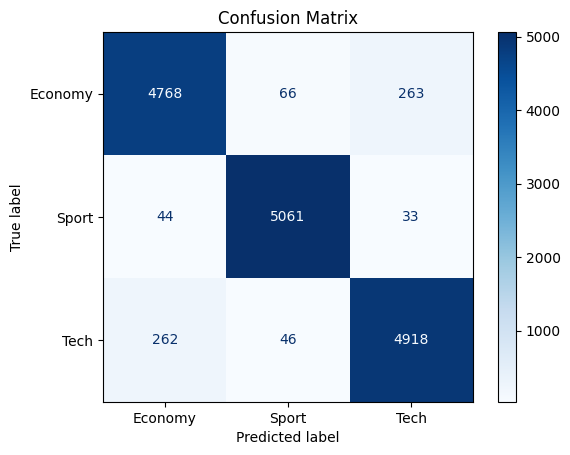

In [11]:
y_pred=[]
for row_text in X_test:
  y_pred.append(nv.predict(row_text))

nv.evalute(y_test, y_pred)